# 05 — Apprendre : de la loss aux gradients, puis à la mise à jour de `W`

**Chapitre 1** · durée conseillée : 25 min · CPU uniquement · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/chapitre_1/05_gradients_et_mise_a_jour.ipynb)

![Parcours du chapitre](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_1/figures/00_parcours.png)

Le réseau sait faire son **forward pass** : pour chaque caractère courant, il produit 27 probabilités. Nous savons **mesurer** son erreur avec la NLL.

**Mais mesurer ne suffit pas à apprendre.** `W` est toujours aléatoire : comment changer ses 729 nombres pour que les bonnes réponses deviennent plus probables ?

Quatre problèmes à résoudre, dans l'ordre :
1. **Quelle probabilité évaluer ?** Celle de la bonne réponse, dans chaque ligne : `probs[torch.arange(n), ys]`.
2. **Quel poids modifier, et dans quel sens ?** C'est ce que disent les dérivées, rangées dans `W.grad` par `loss.backward()`.
3. **De combien ?** C'est le rôle du *learning rate*.
4. **Comment apprendre sur tout le corpus ?** En répétant tout cela dans une boucle (notebook 06).

> **Objectif :** savoir expliquer **chaque ligne** de la boucle d'entraînement, et pas seulement l'exécuter.

In [ ]:
# Sur Google Colab : récupérer le dépôt du cours (corpus + modules partagés comme bigramme.py).
# En local, cette cellule ne fait rien.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("bigramme.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/chapitre_1

In [1]:
# Préparation : imports et petit module partagé du chapitre
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigramme  # fichier bigramme.py, à côté de ce notebook
from bigramme import SEED, plot_matrice_caracteres

words = bigramme.charger_prenoms()
chars, stoi, itos = bigramme.construire_vocabulaire(words)
print(f"{len(words):,} prénoms · vocabulaire de {len(stoi)} symboles · PyTorch {torch.__version__}")

sequence = ["."] + list("emma") + ["."]
transitions = list(zip(sequence, sequence[1:]))
xs_small = torch.tensor([stoi[a] for a, b in transitions])
ys_small = torch.tensor([stoi[b] for a, b in transitions])

W_demo = torch.randn((27, 27), generator=torch.Generator().manual_seed(SEED))
probs_small = F.softmax(F.one_hot(xs_small, 27).float() @ W_demo, dim=1)   # forward du notebook 04
print("probs_small :", tuple(probs_small.shape))

32,033 prénoms · vocabulaire de 27 symboles · PyTorch 2.14.1+cu130
probs_small : (5, 27)


## 1. Dans le tableau des probabilités, quelle case nous intéresse ?

`probs_small` est un tableau de **5 lignes × 27 colonnes** :
- **ligne** = numéro de l'exemple (0 à 4) ;
- **colonne** = caractère que le réseau pourrait prédire (0 à 26) ;
- **valeur** = probabilité prédite pour ce caractère.

La NLL ne regarde **qu'une case par ligne** : celle de la **réponse réellement observée**.

| ligne | caractère donné | bonne réponse | case à lire |
|---|---|---|---|
| 0 | `.` | `e` | `probs_small[0, stoi['e']]` |
| 1 | `e` | `m` | `probs_small[1, stoi['m']]` |
| 2 | `m` | `m` | `probs_small[2, stoi['m']]` |
| 3 | `m` | `a` | `probs_small[3, stoi['a']]` |
| 4 | `a` | `.` | `probs_small[4, stoi['.']]` |

**Pourquoi pas la colonne la plus probable ?** Elle dirait ce que le modèle **préfère**, pas la probabilité qu'il donnait à la **vraie** réponse.

In [2]:
# Méthode explicite : une boucle sur les 5 exemples
probabilites_par_boucle = []
for i in range(len(ys_small)):
    p = probs_small[i, ys_small[i]]
    probabilites_par_boucle.append(p)
    a, b = transitions[i]
    print(f"Exemple {i} : {a} → {b} | case [{i}, {ys_small[i].item():2d}] | p = {p.item():.4f}")
probabilites_par_boucle = torch.stack(probabilites_par_boucle)
print("Forme :", tuple(probabilites_par_boucle.shape), "(une valeur par exemple, pas 27)")

Exemple 0 : . → e | case [0,  5] | p = 0.0123
Exemple 1 : e → m | case [1, 13] | p = 0.0181
Exemple 2 : m → m | case [2, 13] | p = 0.0267
Exemple 3 : m → a | case [3,  1] | p = 0.0737
Exemple 4 : a → . | case [4,  0] | p = 0.0150
Forme : (5,) (une valeur par exemple, pas 27)


### `torch.arange(n)` : des **numéros de lignes**

Pour faire les 5 lectures d'un coup, PyTorch accepte **deux vecteurs d'indices**, associés terme à terme :

```python
probs_small[torch.arange(5), ys_small]
# = [probs_small[0, ys[0]], probs_small[1, ys[1]], ..., probs_small[4, ys[4]]]
```

C'est l'**indexation avancée**. `torch.arange(5)` donne les **numéros des exemples** (0 à 4), pas les 27 caractères. `ys_small` dit quelle colonne lire dans chaque ligne.

**Piège :** `probs_small[:, ys_small]` signifie « toutes les lignes, et ces 5 colonnes ». On obtient un tableau `(5, 5)`, pas 5 valeurs.

Paires (ligne, colonne) : [(0, 5), (1, 13), (2, 13), (3, 1), (4, 0)]
Identique à la boucle ?  True
probs_small[:, ys_small]          : (5, 5)  ← FAUX ici
probs_small[torch.arange(n), ys]  : (5,)


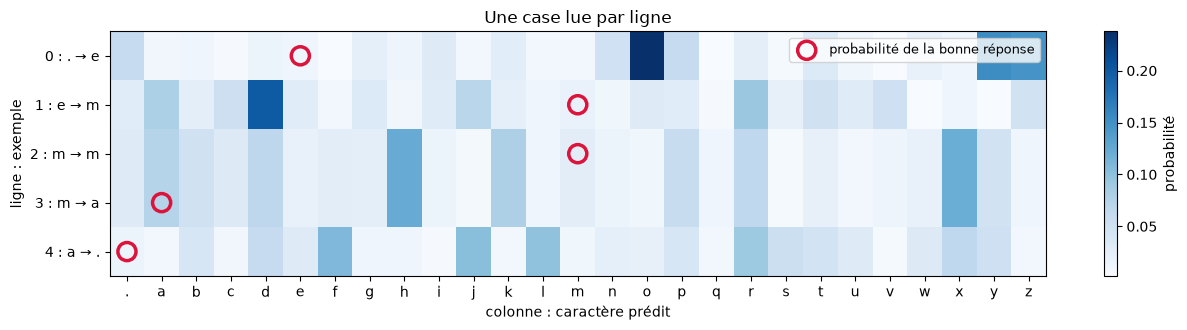

In [3]:
n = len(ys_small)
lignes = torch.arange(n)
probas_correctes = probs_small[lignes, ys_small]
print("Paires (ligne, colonne) :", list(zip(lignes.tolist(), ys_small.tolist())))
print("Identique à la boucle ? ", torch.allclose(probas_correctes, probabilites_par_boucle))
print("probs_small[:, ys_small]          :", tuple(probs_small[:, ys_small].shape), " ← FAUX ici")
print("probs_small[torch.arange(n), ys]  :", tuple(probas_correctes.shape))

fig, ax = plt.subplots(figsize=(13, 3.4))
im = ax.imshow(probs_small, aspect="auto", cmap="Blues")
ax.scatter(ys_small, lignes, s=170, facecolors="none", edgecolors="crimson", linewidths=2.5,
           label="probabilité de la bonne réponse")
ax.set_xticks(range(27), [itos[j] for j in range(27)])
ax.set_yticks(range(n), [f"{i} : {a} → {b}" for i, (a, b) in enumerate(transitions)])
ax.set(xlabel="colonne : caractère prédit", ylabel="ligne : exemple", title="Une case lue par ligne")
ax.legend(loc="upper right", fontsize=9); fig.colorbar(im, ax=ax, label="probabilité")
plt.tight_layout(); plt.show()

## 2. De la loss à ses dérivées

La loss du notebook 02, écrite comme une **fonction de `W`** :

$$
\mathcal L(W)=-\frac{1}{n}\sum_{i=0}^{n-1}\log\big(\mathrm{probs}(W)[i, y_i]\big).
$$

Deux matrices `W` différentes donnent deux losses différentes. Nous voulons savoir **comment la loss varie quand on change un poids précis**. C'est exactement ce que dit la dérivée partielle $\partial \mathcal L / \partial W_{a,b}$, la **pente locale** :
- **positive** : augmenter ce poids fait **monter** la loss ;
- **négative** : augmenter ce poids fait **baisser** la loss ;
- **proche de zéro** : ce poids n'a presque pas d'effet.

Les **729 dérivées partielles** forment le **gradient**. À ne pas confondre : `W` contient les poids, `W.grad` contient les **pentes de la loss** par rapport à ces poids.

Les deux fonctions ci-dessous reprennent exactement le forward du notebook 04 et la NLL du notebook 02 (elles sont aussi dans `bigramme.py`) :

In [4]:
def forward_from_indices(x_indices, weights):
    """Forward pass du bigramme neuronal : indices -> one-hot -> logits -> probabilités."""
    encoded = F.one_hot(x_indices, num_classes=weights.shape[0]).float()  # (n, 27)
    logits = encoded @ weights                                            # (n, 27)
    counts = logits.exp()                                                 # (n, 27), tous > 0
    return counts / counts.sum(dim=1, keepdim=True)                       # (n, 27), lignes de somme 1


def nll_from_probs(probs, targets):
    """NLL moyenne : -log de la probabilité donnée à la bonne réponse, moyennée."""
    n = len(targets)
    bonnes_probas = probs[torch.arange(n), targets]   # (n,) : une probabilité par exemple
    return -bonnes_probas.log().mean()                # scalaire


print("Loss de W_demo sur emma :", round(nll_from_probs(forward_from_indices(xs_small, W_demo), ys_small).item(), 4))

Loss de W_demo sur emma : 3.7693


## 3. `requires_grad`, `backward()` et `W.grad` : qui fait quoi ?

![Forward et backward](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_1/figures/05_graphe_calcul.png)

Pour dériver la loss, PyTorch doit **enregistrer toutes les opérations** qui la relient à `W` : c'est le **graphe de calcul**.

- `W.requires_grad_(True)` : « je veux les dérivées par rapport à `W` ». PyTorch enregistre alors chaque opération du forward.
- `loss.backward()` : part de la loss (un **scalaire**) et **remonte le graphe** en appliquant la règle de dérivation en chaîne. C'est la **rétropropagation** (*backpropagation*).
- `W.grad` : reçoit le gradient, de forme `(27, 27)`. Ce ne sont ni des probabilités ni les nouvelles valeurs de `W`.
- `W.grad = None` : efface le gradient précédent. Sinon, PyTorch **additionne** les gradients de plusieurs appels à `backward()`.

**Crucial : `loss.backward()` ne modifie pas les poids.** Il calcule seulement les pentes. La modification vient après, et c'est nous qui l'écrivons.

In [5]:
W = W_demo.clone().requires_grad_(True)     # même départ que plus haut, mais suivi par autograd

loss = nll_from_probs(forward_from_indices(xs_small, W), ys_small)
print("Gradient avant backward :", W.grad)
loss.backward()
print("Gradient après backward : forme", tuple(W.grad.shape))

row, col = stoi["."], stoi["e"]
old_weight = W[row, col].item()
print(f"W['.', 'e']        = {old_weight:+.5f}   (le poids)")
print(f"∂loss/∂W['.', 'e'] = {W.grad[row, col].item():+.5f}   (la pente)")
print("Le poids a-t-il changé ?", W[row, col].item() != old_weight)

Gradient avant backward : None
Gradient après backward : forme (27, 27)
W['.', 'e']        = -0.02964   (le poids)
∂loss/∂W['.', 'e'] = -0.19754   (la pente)
Le poids a-t-il changé ? False


Le gradient de `W['.', 'e']` est **négatif** : augmenter ce poids ferait **baisser** la loss. C'est logique, car `. → e` est une vraie transition d'`emma`. Augmenter ce score augmente la probabilité de la bonne réponse.

### Vérification : `backward()` calcule bien une dérivée

On peut vérifier une valeur de `W.grad` avec une **différence finie**. On bouge un poids de $\pm\varepsilon$ et on mesure la variation de la loss :

$$
\frac{\partial\mathcal L}{\partial W_{a,b}} \approx \frac{\mathcal L(W_{a,b}+\varepsilon)-\mathcal L(W_{a,b}-\varepsilon)}{2\varepsilon}.
$$

Cette méthode demande deux forward **par poids**. Elle sert à **vérifier**, pas à entraîner. Pour 729 poids, il faudrait 1 458 forward. Un seul `backward()` calcule **toutes** les dérivées d'un coup.

In [6]:
eps = 1e-3
with torch.no_grad():
    W_plus, W_moins = W.detach().clone(), W.detach().clone()
    W_plus[row, col] += eps
    W_moins[row, col] -= eps
    l_plus = nll_from_probs(forward_from_indices(xs_small, W_plus), ys_small)
    l_moins = nll_from_probs(forward_from_indices(xs_small, W_moins), ys_small)

pente_finie = ((l_plus - l_moins) / (2 * eps)).item()
print(f"Différence finie : {pente_finie:+.6f}")
print(f"backward()       : {W.grad[row, col].item():+.6f}")
assert abs(pente_finie - W.grad[row, col].item()) < 1e-3

Différence finie : -0.197649
backward()       : -0.197543


### Ce que calcule `backward()`, à la main

Vous savez dériver : faisons-le. Pour un exemple de bonne réponse $y$, avec $p = \mathrm{softmax}(z)$ :

$$
\mathcal L_i = -\log p_y = -z_y + \log\sum_k e^{z_k}
\qquad\Rightarrow\qquad
\frac{\partial \mathcal L_i}{\partial z_j} = p_j - \mathbb 1[j = y].
$$

En moyenne sur les $n$ exemples, et puisque `logits = xenc @ W` :

$$
\frac{\partial \mathcal L}{\partial\,\mathrm{logits}} = \frac{\mathrm{probs} - \mathrm{one\_hot}(y)}{n},
\qquad
\frac{\partial \mathcal L}{\partial W} = \mathrm{xenc}^\top\,\frac{\partial \mathcal L}{\partial\,\mathrm{logits}}.
$$

**Interprétation :**
- la **bonne réponse** reçoit une pente $p_y - 1 < 0$ : son score **monte** à la mise à jour ;
- **chaque mauvaise réponse** reçoit une pente $p_j > 0$, proportionnelle à sa probabilité : son score **baisse**, d'autant plus que le modèle y croyait ;
- les lignes de `W` des caractères **absents** des entrées reçoivent un gradient **nul**.

In [7]:
xenc = F.one_hot(xs_small, 27).float()
with torch.no_grad():
    probs = forward_from_indices(xs_small, W)
    dlogits = (probs - F.one_hot(ys_small, 27).float()) / len(ys_small)
    dW = xenc.T @ dlogits

print("Gradient à la main == W.grad ?", torch.allclose(dW, W.grad, atol=1e-6))
lignes_actives = (W.grad.abs().sum(dim=1) > 0).nonzero().flatten().tolist()
print("Lignes de W qui reçoivent un gradient :", [itos[i] for i in lignes_actives], "(les entrées de 'emma')")

Gradient à la main == W.grad ? True
Lignes de W qui reçoivent un gradient : ['.', 'a', 'e', 'm'] (les entrées de 'emma')


## 4. La mise à jour : soustraire `learning_rate × grad`

Pour faire **baisser** la loss, on fait un pas dans la direction **opposée** au gradient :

$$
\boxed{W_{\text{nouveau}} = W_{\text{ancien}} - \eta\,\nabla_W\mathcal L}
$$

$\eta$ (`learning_rate`) fixe la **taille du pas**, pas sa direction :
- **petit** : progrès sûrs mais lents ;
- **plus grand** : progrès plus rapides ;
- **trop grand** : on dépasse la bonne région, on oscille, ou on diverge.

Exemple avec un seul poids : `W[a,b] = 0,40`, `W.grad[a,b] = +0,20`, `lr = 0,1` donne $0{,}40 - 0{,}1\times0{,}20 = 0{,}38$. Gradient positif, donc le poids **diminue**. Une mise à jour change **tous** les poids, chacun selon sa propre pente.

La direction $-\nabla\mathcal L$ fait baisser la loss **localement**, pour un pas assez petit. Un très grand pas n'a aucune garantie.

In [8]:
print(f"Loss de départ : {loss.item():.4f}")
for lr in [0.0, 0.1, 1.0, 10.0, 100.0, 1000.0]:
    with torch.no_grad():
        l = nll_from_probs(forward_from_indices(xs_small, W - lr * W.grad), ys_small).item()
    print(f"  learning_rate = {lr:>6} → loss après UN pas = {l:.4f}")

Loss de départ : 3.7693
  learning_rate =    0.0 → loss après UN pas = 3.7693
  learning_rate =    0.1 → loss après UN pas = 3.7492
  learning_rate =    1.0 → loss après UN pas = 3.5694
  learning_rate =   10.0 → loss après UN pas = 1.9317
  learning_rate =  100.0 → loss après UN pas = 0.3135
  learning_rate = 1000.0 → loss après UN pas = nan


Sur 5 exemples seulement, la loss baisse de plus en plus jusqu'à `lr = 100` (0,31 !). Avec si peu de données, le modèle peut presque les apprendre par cœur en un seul grand pas. Avec `1000`, les logits deviennent énormes, `exp` déborde et la loss vaut `nan` : le pas est absurde. Sur le corpus entier (notebook 06), les pas utiles seront beaucoup plus modestes.

On effectue maintenant **un vrai pas**. On l'écrit sous `torch.no_grad()` : la mise à jour n'a pas à être enregistrée dans le graphe de calcul, ce n'est pas une opération du modèle.

In [9]:
lr = 1.0
with torch.no_grad():
    W -= lr * W.grad

loss_apres = nll_from_probs(forward_from_indices(xs_small, W), ys_small)
print(f"Loss avant : {loss.item():.4f}  →  après un pas : {loss_apres.item():.4f}")
print(f"W['.', 'e'] : {old_weight:+.4f} → {W[row, col].item():+.4f}")
assert loss_apres.item() < loss.item()

Loss avant : 3.7693  →  après un pas : 3.5694
W['.', 'e'] : -0.0296 → +0.1679


## Bilan : une itération d'apprentissage

| étape | code | rôle |
|---|---|---|
| forward | `probs = forward_from_indices(xs, W)` | prédire |
| loss | `loss = nll_from_probs(probs, ys)` | noter |
| remise à zéro | `W.grad = None` | ne pas cumuler les gradients |
| backward | `loss.backward()` | calculer les 729 pentes |
| mise à jour | `W -= lr * W.grad` sous `no_grad` | corriger les poids |

**Questions de vérification :**
1. `loss.backward()` modifie-t-il `W` ? → Non, il remplit `W.grad`.
2. Si `W.grad[a,b] > 0`, que devient `W[a,b]` ? → Il **diminue** (signe moins).
3. Pourquoi seules 4 lignes de `W` ont reçu un gradient ? → Seuls `.`, `e`, `m` et `a` sont des **entrées** d'`emma`.

**Notebook 06 :** répéter ces cinq étapes sur les 228 146 bigrammes du corpus et voir si `W` retrouve la table `P`.

## Références
- D. E. Rumelhart, G. E. Hinton et R. J. Williams, [*Learning representations by back-propagating errors*](https://www.nature.com/articles/323533a0), Nature, 1986.
- Andrej Karpathy, [*The spelled-out intro to neural networks and backpropagation: building micrograd*](https://www.youtube.com/watch?v=VMj-3S1tku0) (2022) : la rétropropagation recodée de zéro.
- 3Blue1Brown, [*Backpropagation calculus*](https://www.youtube.com/watch?v=tIeHLnjs5U8) : l'intuition visuelle de la règle de la chaîne.
- I. Goodfellow, Y. Bengio et A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), 2016, sections 4.3 (descente de gradient) et 6.5 (rétropropagation).
- Documentation PyTorch : [*A Gentle Introduction to torch.autograd*](https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html).